## To create tSZ maps for Cluster129

Codes from https://github.com/weiguangcui/pymsz

In [15]:
import numpy as np
import h5py
import pymsz
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from astropy.io import fits

h = 0.678

path = '/data20/TheThreeHundred/data_NewICs/simulations/GIZMO_7k/NewMDCLUSTER_0129/'
fhist = 'Historic_data_324.hdf5'

#CENTER = np.array([500000, 500000, 500000], dtype=np.float32)  # cluster centre, sim units (kpc/h)
RADIUS = 10000.0  # extraction radius, kpc/h
snaps = [47,52,54,55,78]


In [23]:
#snaps = [47,52,54,55,78]
snaps = [52]
clusid = 129
for snap in snaps:

    print(f'Processing snapshot {snap}')
    
    with h5py.File(fhist, 'r') as f:
        CENTER = f['cluster_0129/pos'][()][128-snap] # position of progenitor at current snapshot
        #RADIUS = f['R200c'][()][128-snap]*5 # 
    
    sim = pymsz.load_data(
        f"{path}snap_{snap:03d}.hdf5",   # base filename (no need for multi-file suffixes)
        snapshot='hdf5',           # set snapshot='hdf5' explicitly if it's HDF5/GIZMO format
        center=CENTER,
        radius=RADIUS,
        cut_sfr=0.1,              # exclude particles with SFR above this (removes spurious hot/cold gas), Msun/yr
        restrict_r=False,         # False = cut a cube of side 2*radius; True = an exact sphere
    )
    
    z = sim.cosmology["z"]
    print("Snapshot redshift:", z)

    ## comput map! 

        
    pj_tsz = pymsz.TT_model(
        sim,
        label='tSZ',
        npixel='auto',        # or an integer, e.g. 500
        axis='z',              # 'x', 'y', 'z', or [alpha, beta, gamma] rotation angles in degrees
        neighbours=64,          # SPH smoothing neighbours (ignored if HSML is in the snapshot)
        redshift=z,             # redshift to "place" the cluster at, for angular-diameter-distance scaling
        AR=5.0,                 # angular resolution in arcsec -> sets pixel size (only if npixel='auto')
        Ncpu=4,                 # parallelize the SPH smoothing
        sph_kernel='cubic',
        Memreduce=True,
    )
    
    pj_tsz.write_fits_image(f"tsz-map/cluster129_tSZ_snap{snap}.fits", overwrite=True,
                             comments=f"Simulation redshift: {z:.2f}")    

Processing snapshot 52
reading files:  ['/data20/TheThreeHundred/data_NewICs/simulations/GIZMO_7k/NewMDCLUSTER_0129/snap_052.hdf5']
Reading /data20/TheThreeHundred/data_NewICs/simulations/GIZMO_7k/NewMDCLUSTER_0129/snap_052.hdf5 file with Header
Snapshot redshift: 4.385029629996624
Convert the neighbor count in pixel size:  5.746768975186917
Init smoothing, RAM=1.139 GB
After cKDTree , RAM=1.295 GB
Directly pass the cKDTree to tasks with Python version 3.8.10 (default, Jun  4 2021, 15:09:15) 
[GCC 7.5.0]


### Plot the map from fits

In [71]:
from set_style import set_style

In [32]:
#from astropy.cosmology import Planck18 as cosmo
from astropy.cosmology import FlatLambdaCDM

cosmo = FlatLambdaCDM(H0=67.8, Om0=0.31)



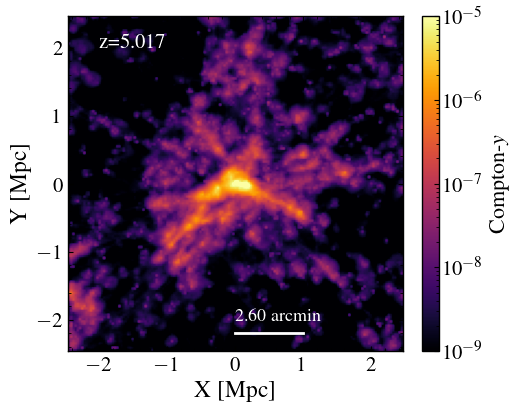

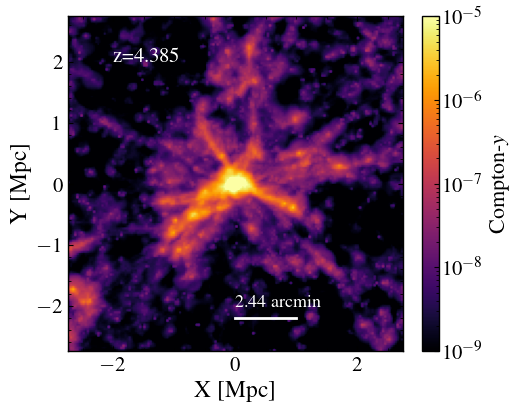

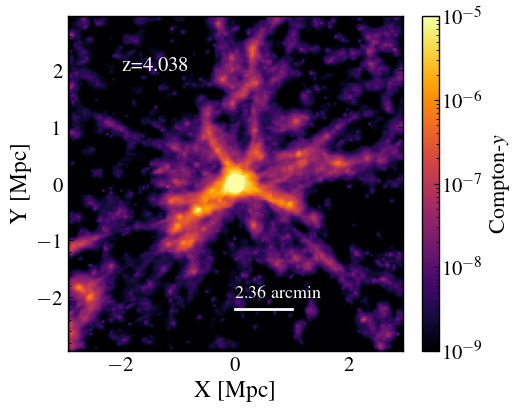

In [319]:
fs = 17

set_style('mnras')

#for snap in snaps:
for snap in [47,52,55]:

    fits_file = f"tsz-map/cluster129_tSZ_snap{snap}.fits"
    png_file  = f"tsz-map/cluster129_tSZ_snap{snap}.png"
    
    with fits.open(fits_file, ignore_missing_simple=True) as hdul:
        hdr  = hdul[0].header
        ymap = hdul[0].data
    
    pixsize_kpc = hdr["PSIZE"]      # kpc/pixel at simulation time
    redshift    = hdr["REDSHIFT"]
    aglres      = hdr["AGLRES"]     # arcsec/pixel
    ang_size = cosmo.arcsec_per_kpc_proper(redshift).value*1000/60 # arcmin / Mpc (proper)
    
    ny, nx = ymap.shape
    extent_mpc = [-(nx/2)*pixsize_kpc/1000, (nx/2)*pixsize_kpc/1000,
                  -(ny/2)*pixsize_kpc/1000, (ny/2)*pixsize_kpc/1000]

    vmin, vmax = 1e-10,1e-4
    fig, ax = plt.subplots(1,1, figsize=(6, 4))
    im = ax.imshow(ymap, origin="lower", cmap="inferno",
                   norm=LogNorm(vmin=1e-9,
                                vmax=1e-5),
                   extent=extent_mpc)
    
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, )
    cbar.set_label(r"Compton-$y$", fontsize=fs-1)
    cbar.ax.tick_params(labelsize=fs-2)
    ax.set_xlabel("X [Mpc]", fontsize=fs)
    ax.set_ylabel("Y [Mpc]", fontsize=fs)
    #ax.set_title(f"$z={redshift:.3f}$"
     #            f"  (1 Mpc = {ang_size:.2f} arcmin)", fontsize=fs+1)
    ax.plot([0,1], [-2.2,-2.2], lw=2, color='white', ls='-')
    ax.text(0,-2, f'{ang_size:.2f} arcmin', color='white', fontsize=fs-4)
    ax.text(-2,2, f'z={redshift:.3f}', color='white', fontsize=fs-2)
    ax.tick_params(labelsize=fs-2)
    
    plt.savefig(png_file, dpi=250, bbox_inches='tight')
    #plt.show()

## Compute integrated Y500 

In [17]:
import os


h = 0.678

path = '/data20/TheThreeHundred/data_NewICs/simulations/GIZMO_7k/NewMDCLUSTER_0129/'
fhist = 'Historic_data_324.hdf5'

path_500 = '/data20/TheThreeHundred/data_NewICs/catalogues/AHF/GIZMO_7k_R500c/NewMDCLUSTER_0129/'



In [30]:
def get_filename(snap=55):
    
        dirlist = [fname for fname in os.listdir(path_500) if fname.startswith(f"C500_snap_{snap:03d}") and fname.endswith('_halos')]
        return dirlist[0]

def get_id(snap=55):
    
    with h5py.File('HaloID_track_Gizmo7k.hdf5','r') as f:
        ID = f['cluster_0129/id_list'][128-snap]
        z = f['z'][128-snap]
        return ID, z

def get_R500(snap=55):

    fname = get_filename(snap)
    HostID, z = get_id(snap)

    a_t = 1./(1+z)
    ID, M500, R500 = np.genfromtxt(path_500+fname, usecols=[0,3,11], skip_header=1, unpack=True)

    index = np.where(ID == HostID)[0][0]

    return M500[index], R500[index]#*a_t/h

def get_center(snap=55):
    with h5py.File(fhist, 'r') as f:
        CENTER = f['cluster_0129/pos'][()][128-snap] # position of progenitor at current snapshot

    return CENTER
    

    

In [105]:

def compute_Y500(snap, aperture=None):

    # Integrate Compton-y emission within aperture.
    h = 0.678
    CENTER = get_center(snap)
    M500, R500 = get_R500(snap)
    
    if aperture == None:
        RADIUS = R500
    else:
        RADIUS = aperture*h/(1/(1+4.38))
    
    simd = pymsz.load_data(
        f"{path}snap_{snap:03d}.hdf5",   # base filename (no need for multi-file suffixes)
        snapshot='hdf5',           # set snapshot='hdf5' explicitly if it's HDF5/GIZMO format
        center=CENTER,
        radius=RADIUS,
        cut_sfr=0.1,              # exclude particles with SFR above this (removes spurious hot/cold gas), Msun/yr
        restrict_r=False,         # False = cut a cube of side 2*radius; True = an exact sphere
    )
    
    simd.prep_ss_TT()
    h, z = simd.cosmology['h'], simd.cosmology['z']
    
    ang_size = cosmo.arcsec_per_kpc_proper(z).value*1000/60 # arcmin / Mpc (proper)
    
    # 1) spherical Y500: direct particle sum
    r = np.sqrt((simd.pos**2).sum(1)) / h / (1+z)      # proper kpc
    Y500_sph = simd.Tszdata[r < RADIUS].sum() / 1e6      # Mpc^2
    
    # 2) cylindrical Y500: aperture on the map
    m = pymsz.TT_model(simd, npixel=200, axis='z', Ncpu=4, Memreduce=True)
    n = m.ydata.shape[0]
    x = (np.arange(n) + 0.5 - n/2) * m.pxs             # proper kpc
    X, Y = np.meshgrid(x, x, indexing='ij')
    Y500_cyl = m.ydata[np.hypot(X, Y) < RADIUS].sum() * m.pxs**2 / 1e6

    return Y500_sph, Y500_cyl, ang_size, z



In [269]:
compute_Y500(snap=52, aperture=626)

reading files:  ['/data20/TheThreeHundred/data_NewICs/simulations/GIZMO_7k/NewMDCLUSTER_0129/snap_052.hdf5']
Reading /data20/TheThreeHundred/data_NewICs/simulations/GIZMO_7k/NewMDCLUSTER_0129/snap_052.hdf5 file with Header
Init smoothing, RAM=4.587 GB
After cKDTree , RAM=4.587 GB
Directly pass the cKDTree to tasks with Python version 3.8.10 (default, Jun  4 2021, 15:09:15) 
[GCC 7.5.0]


(2.9611845016479494e-06,
 2.9653716632425308e-06,
 2.4412745794125734,
 4.385029629996624)

In [236]:
apertures_comovil = np.logspace(1,2.3,10)*h/a_t # ckpc/h
Y500_aper = np.zeros(len(apertures))
ang_size_aper = np.zeros(len(apertures))

for i, aper in enumerate(apertures_comovil):
    Y500_aper[i],_, ang_size_aper[i], _ = compute_Y500(snap=52, aperture=aper)

reading files:  ['/data20/TheThreeHundred/data_NewICs/simulations/GIZMO_7k/NewMDCLUSTER_0129/snap_052.hdf5']
Reading /data20/TheThreeHundred/data_NewICs/simulations/GIZMO_7k/NewMDCLUSTER_0129/snap_052.hdf5 file with Header
Init smoothing, RAM=4.634 GB
After cKDTree , RAM=4.634 GB
Directly pass the cKDTree to tasks with Python version 3.8.10 (default, Jun  4 2021, 15:09:15) 
[GCC 7.5.0]
reading files:  ['/data20/TheThreeHundred/data_NewICs/simulations/GIZMO_7k/NewMDCLUSTER_0129/snap_052.hdf5']
Reading /data20/TheThreeHundred/data_NewICs/simulations/GIZMO_7k/NewMDCLUSTER_0129/snap_052.hdf5 file with Header
Init smoothing, RAM=4.634 GB
After cKDTree , RAM=4.634 GB
Directly pass the cKDTree to tasks with Python version 3.8.10 (default, Jun  4 2021, 15:09:15) 
[GCC 7.5.0]
reading files:  ['/data20/TheThreeHundred/data_NewICs/simulations/GIZMO_7k/NewMDCLUSTER_0129/snap_052.hdf5']
Reading /data20/TheThreeHundred/data_NewICs/simulations/GIZMO_7k/NewMDCLUSTER_0129/snap_052.hdf5 file with Header

## tSZ signal vs aperture. Comparison to self-similar relation

In [ ]:
'''# compute accumulated total mass
particle_data = read_particle_simulation(129,52)

center = get_center(snap=52)
center *= a_t/h

apertures = np.logspace(1,2.3,20) # physical kpc
total_mass, bin_x = compute_accumulated_mass(particle_data, center, apertures=apertures) 
from scipy.interpolate import interp1d

mass_interp = interp1d(bin_x, total_mass, kind='cubic', bounds_error=False,
                    fill_value=np.nan)
'''

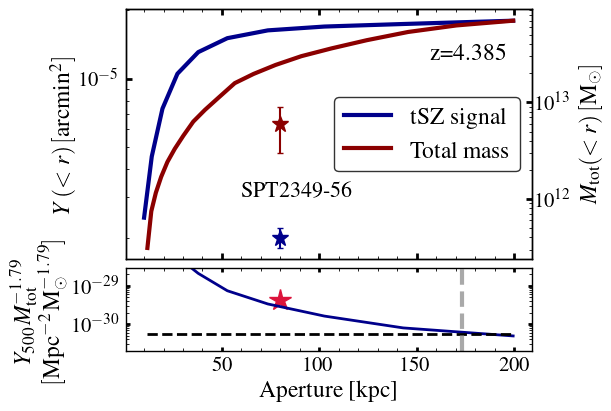

In [320]:
E_z = 7. # H(z)/H0
self_similar_cte = (7.5e14)**(-1.79)*E_z**(2./3)/10**0.2*1e-4
R500_cluster129 = 173 # kpc

# Different apertures estimation
set_style('mnras')
fig, (ax, ax_lower) = plt.subplots(
    2, 1,
    figsize=(6, 4),
    gridspec_kw={'height_ratios': [4.5, 1.5]},
    sharex=True
)

fs = 17
ax.set_ylabel(r'$Y\, (<r) \, [{\rm arcmin^2}]$', fontsize=fs)
ax.set_yscale('log')
ax.tick_params(labelsize=fs-2, length=4, width=2)

aper_phys = apertures_comovil*a_t/h

ax.plot(aper_phys, Y500_aper*ang_size_aper**2, lw=3, label='tSZ signal', color='darkblue')
ax.errorbar([80], [2e-6], yerr=[0.2e-6], ls=None, ms=12, capsize=2, marker='*', color='darkblue')

ax.text(0.75,0.8, 'z=4.385', fontsize=fs, transform=ax.transAxes)
ax.text(60, 3e-6, 'SPT2349-56', fontsize=fs-1)

ax2 = ax.twinx()
ax2.set_ylabel(r'$M_{\rm tot} (<r) \, [{\rm M_\odot}]$', fontsize=fs)
ax2.set_yscale('log')
ax2.tick_params(labelsize=fs-2, length=4, width=2)
ax2.plot(bin_x, total_mass, lw=3, label='Total mass', color='darkred')

ax2.errorbar([80], [6e12], yerr=[[3e12],[3e12]], ls=None, ms=12, capsize=2, marker='*', color='darkred')

handles1, labels1 = ax.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

ax.legend(handles1 + handles2, labels1 + labels2, loc='center right', fontsize=fs)

# Lower panel -- self-similar relation
ax_lower.set_xlabel('Aperture [kpc]', fontsize=fs)
ax_lower.set_ylabel(r'$Y_{500}\, M_{\rm tot}^{-1.79} \newline \, [{\rm Mpc^{-2} \, M_\odot^{-1.79}}]$', fontsize=fs)
ax_lower.set_yscale('log')
ax_lower.tick_params(labelsize=fs-2, length=3, width=2)


ax_lower.plot([80], [2e-6]/ang_size_aper[0]**2*(6.2e12)**(-1.79), ls=None, ms=16, marker='*', color='crimson')
ax_lower.plot(aper_phys, Y500_aper*mass_interp(aper_phys)**(-1.79), lw=2, color='darkblue')
ax_lower.plot(bin_x, np.full(len(bin_x),self_similar_cte) , lw=2, ls='--', color='black')
ax_lower.axvline(R500_cluster129, lw=3, ls='--', color='darkgray')
ax_lower.set_ylim([2e-31,3e-29])

plt.savefig('tsz-map/tSZ_aperture_mass.png',dpi=200)

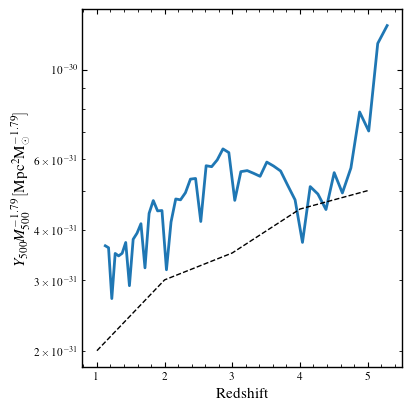

In [89]:
# self similar evolution?
fig, ax = plt.subplots(1,1, figsize=(4,4))

fs = 11
ax.set_ylabel(r'$Y_{500} M_{500}^{-1.79} \, [{\rm Mpc^2 M_\odot^{-1.79}}]$', fontsize=fs)
ax.set_xlabel('Redshift', fontsize=fs)

ax.set_yscale('log')

ax.plot(z_list, Y500/((np.array(M500_list)/h)**1.79), lw=2)
ax.plot(x_self, y_self, lw=1, ls='--', color='black')

plt.savefig('tsz_self_similar.png',dpi=200)


In [181]:
m500, r500 = get_R500(snap=52)

In [237]:
r500/h*a_t

171.53241687962026

In [192]:
Y500_aper

array([1.29033148e-07, 7.38850355e-07, 1.42663515e-06, 2.55315518e-06,
       2.85405993e-06, 2.90438032e-06, 2.99883080e-06, 3.07611847e-06,
       3.09857368e-06])

In [193]:
with h5py.File('data/tSZ_Y500_evolution.hdf5','r') as f:
    y500_test = f['Y500'][()]
    m500_test = f['M500'][()]
    z_test = f['z'][()]

In [268]:
b

626.27

In [203]:
y500_test[7]/((m500_test[7]/h)**1.79)

4.4908761679908205e-31

In [178]:
Y500_aper[5]/((np.array(m500/h))**1.79)

2.6831552986826804e-31

In [87]:
x_self = [1,2,3,4,5]
y_self = np.array([2,3,3.5,4.5,5])*1e-31

In [90]:
with h5py.File('tSZ_Y500_evolution.hdf5', 'w') as f:
    f['Y500'] = Y500
    f['z'] = z_list
    f['ang_size'] = ang_size_list
    f['M500'] = M500_list

    

In [207]:
KPC_CM = 3.085678e21
MSUN_G = 1.98841e33

def read_header(f):
    """Return a dict with cosmology and unit information from a GIZMO snapshot."""
    h = f["Header"].attrs
    hdr = {
        "a": float(h["Time"]),
        "z": float(h["Redshift"]),
        "h": float(h["HubbleParam"]),
        "box": float(h["BoxSize"]),
        "mass_table": np.array(h["MassTable"], dtype=float),
        # GIZMO defaults if the unit attributes are not written in the header
        "unit_length_cgs": float(h.get("UnitLength_In_CGS", KPC_CM)),
        "unit_mass_cgs": float(h.get("UnitMass_In_CGS", 1.0e10 * MSUN_G)),
        "unit_velocity_cgs": float(h.get("UnitVelocity_In_CGS", 1.0e5)),
    }
    # code length unit expressed in kpc (comoving, /h implied)
    hdr["code_len_kpc"] = hdr["unit_length_cgs"] / KPC_CM
    # code mass unit -> Msun (h removed)
    hdr["code_mass_msun"] = hdr["unit_mass_cgs"] / MSUN_G / hdr["h"]
    return hdr

def read_particle_simulation(cluster, snap):

    particle_data = {}
    
    path = '/data20/TheThreeHundred/data_NewICs/simulations/GIZMO_7k/'
        
    with h5py.File(path+f'NewMDCLUSTER_{cluster:04d}/snap_{snap:03d}.hdf5', 'r') as f:
    
        hdr = read_header(f)
        z = hdr['z']
        mass_conv = 1e10/h
        a_t = 1/(1.+hdr['z'])
        
        #gas_haloID = f['PartType0/HaloID'][()]
        #dm_haloID = f['PartType1/HaloID'][()]
    
        particle_data['Coordinates_dm'] = f['PartType1/Coordinates'][()]*a_t/h
        particle_data['M_dm'] = f['PartType1/Masses'][()]*mass_conv
        particle_data['Coordinates_gas'] = f['PartType0/Coordinates'][()]*a_t/h
        particle_data['Mgas'] = f['PartType0/Masses'][()]*mass_conv
        particle_data['Mstar'] = f['PartType4/Masses'][()]*mass_conv
        particle_data['Coordinates_stars'] = f['PartType4/Coordinates'][()]*a_t/h
    

    return particle_data  

def compute_accumulated_mass(particle_data, center, apertures=None):

    from scipy.stats import binned_statistic

    # center in physical kpc

    #bins = [0,10,20,50,80,100,150,200,400,500,700, 800, 923,1000]
    bins = apertures
    
    r_dm = np.linalg.norm(particle_data['Coordinates_dm']-center, axis=1)
    r_stars = np.linalg.norm(particle_data['Coordinates_stars']-center, axis=1)
    r_gas = np.linalg.norm(particle_data['Coordinates_gas']-center, axis=1)

    dm_shell, bin_edges, _ = binned_statistic(r_dm, particle_data['M_dm'], statistic='sum', bins=bins)
    star_shell, bin_edges, _ = binned_statistic(r_stars, particle_data['Mstar'], statistic='sum', bins=bins)
    gas_shell, bin_edges, _ = binned_statistic(r_gas, particle_data['Mgas'], statistic='sum', bins=bins)

    dm_total = np.cumsum(dm_shell)
    star_total = np.cumsum(star_shell)
    gas_total = np.cumsum(gas_shell)

    total_mass = dm_total+star_total+gas_total

    bin_x = bin_edges[1:] # as it is enclosed mass

    return total_mass, bin_x
    



In [120]:
z = 4.385
a_t = 1/(1+z)
h = 0.678

In [168]:
particle_data = read_particle_simulation(129,52)

center = get_center(snap=52)
center *= a_t/h

#total_mass, bin_x = compute_accumulated_mass(particle_data, center) 

In [259]:
apertures = np.logspace(1,2.3,20) # physical kpc
total_mass, bin_x = compute_accumulated_mass(particle_data, center, apertures=apertures) 

In [251]:
# to build the interpolator, must reach higher appertures

apertures = np.logspace(1,2.5,20) # physical kpc
total_mass, bin_x = compute_accumulated_mass(particle_data, center, apertures=apertures) 
from scipy.interpolate import interp1d

mass_interp = interp1d(bin_x, total_mass, kind='cubic', bounds_error=False,
                    fill_value=np.nan)